# GR-GAS：b(t)、累计信息增益与参数稳定性

复用 b 值估计 notebook 的对比绘图逻辑和项目共享 `plot_b_value`，沿用累计似然 notebook 的信息增益比较思路。只读取已保存结果，不重训、不运行粒子滤波。所有 b 轨迹保持原始预测值，`smooth=False`，未降采样。

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/"src").exists() and (p/"experiments").exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from scripts.analyze.plot_magnitude_dynamics import (
    load_results, plot_b_timeline, plot_b_metrics,
    plot_cumulative_gain, plot_sensitivity,
)
results=load_results(ROOT)
print("Loaded all four catalog/Mc groups; five original fits and one fitted GAS model each.")

Loaded all four catalog/Mc groups; five original fits and one fitted GAS model each.


## 数据和比较口径

NLL 为每事件报告格点负对数概率。GAS 是多个初始值优化后、按训练似然选出的一个模型；五个初始值不是五个独立统计重复。下表原模型行是五个冻结拟合的均值。

In [2]:
scores=pd.read_csv(results["base"]/"reports/dynamics/test_summary.csv")
display(scores[scores.model.isin(["original_GR","gr_free"])][["region","variant","model","nll_event","mean_probability_TV","events","fits"]])

,region,variant,model,nll_event,mean_probability_TV,events,fits
1,scsn,main,gr_free,4.849313,0.008384,5005.0,1
3,scsn,main,original_GR,4.854743,0.013799,5005.0,5
7,scsn,sensitivity,gr_free,4.782017,0.006403,1897.0,1
9,scsn,sensitivity,original_GR,4.782998,0.015641,1897.0,5
13,swc,main,gr_free,2.530847,0.006100,1261.0,1
15,swc,main,original_GR,2.535980,0.008997,1261.0,5
19,swc,sensitivity,gr_free,2.461960,0.006034,445.0,1
21,swc,sensitivity,original_GR,2.462994,0.013586,445.0,5


## 原始 b 轨迹

深灰为原 NN-GR 的 seed 0，浅灰为其余四次拟合，蓝色为 GR-GAS。左侧包括完整测试期，右侧固定为测试期起始的 180 天，不根据模型表现挑选片段。b_i 在观测第 i 个震级前已确定，图中附在目标事件日期；连接折线不是连续时间光滑性的证明。

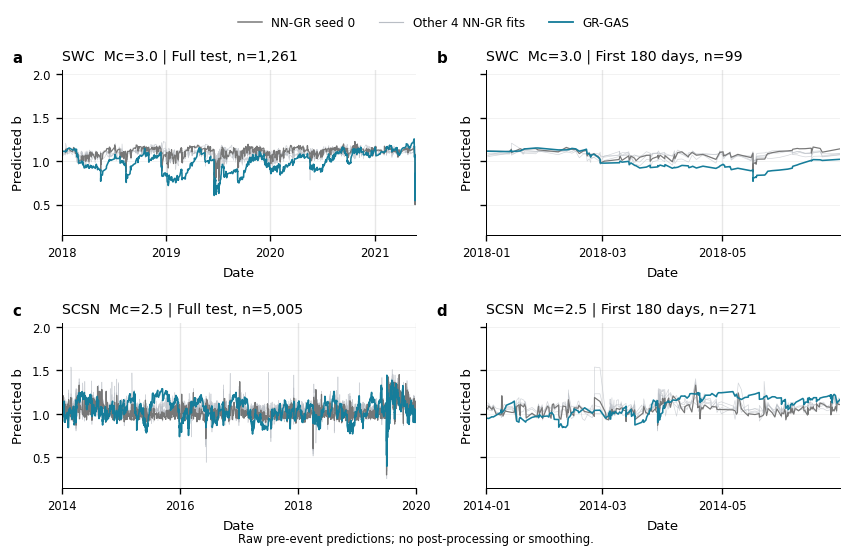

In [3]:
fig=plot_b_timeline(results,"main")
plt.show()
plt.close(fig)

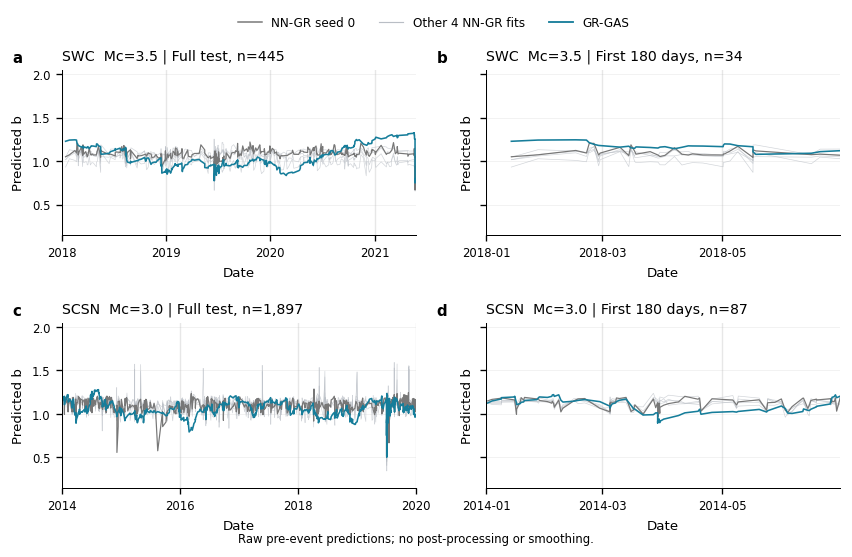

In [4]:
fig=plot_b_timeline(results,"sensitivity")
plt.show()
plt.close(fig)

## 短期跳动与长期振幅

左侧是相邻预测的平均绝对差，右侧是整段测试期 b 的标准差。小空心圆为原模型各拟合，大空心圆为五次拟合均值，蓝色菱形为 GAS。没有把拟合波动画成置信区间；相邻跳动减少不等于整段标准差降低。

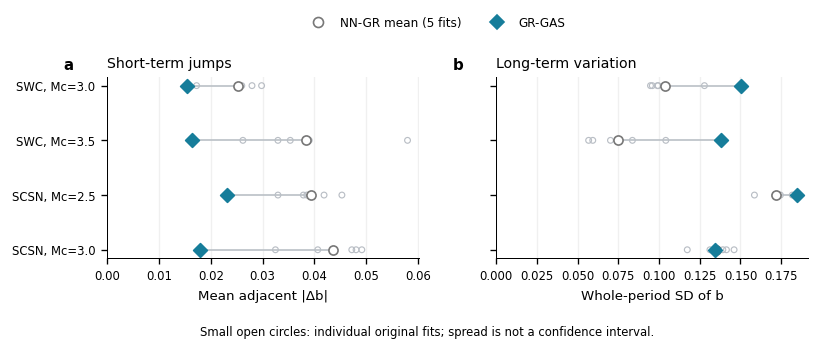

In [5]:
fig=plot_b_metrics(results)
plt.show()
plt.close(fig)

## 震级部分的累计信息增益

逐事件累加 `log p_GAS - log p_NN`，只比较同一报告精度的震级概率。每条浅灰线针对一个原模型拟合，蓝线为五条曲线的平均；正值有利于 GAS。现有配对时间块区间包含零，图中的点估计不代表统计显著。

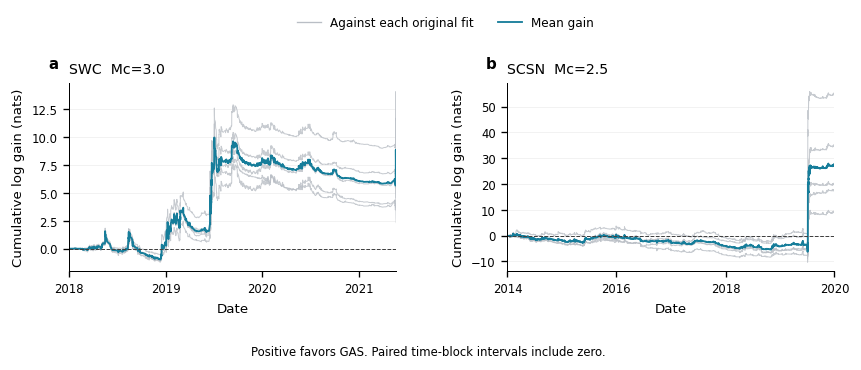

In [6]:
fig=plot_cumulative_gain(results)
plt.show()
plt.close(fig)

## 初始化与已学习参数的敏感性

上排：五个优化起点的验证 NLL 减去其中最小值，纵轴单位为 10^-6；H 初值为 16/64/256/1024/4096，α 初值同时变化。下排：不重新拟合，将已学 H 或 α 乘 0.25/0.5/1/2/4，在验证集上的 NLL 相对默认值的差。初始化稳定不等于任意放大参数都不影响得分。

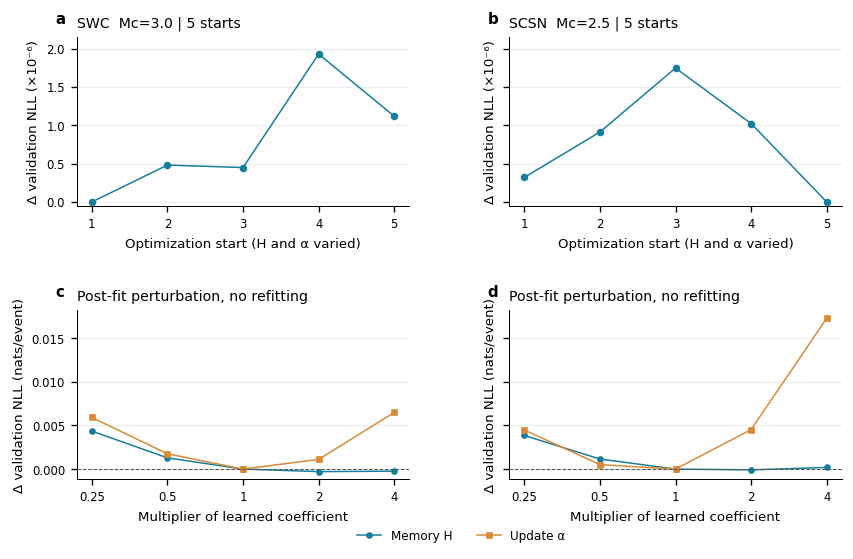

In [7]:
fig=plot_sensitivity(results)
plt.show()
plt.close(fig)

## 导出

图保存到 `notebooks/figs/gr_gas_comparison/`，格式为 PNG、PDF 和可编辑文字 SVG。源数据和图形口径保存到 `notebooks/metrics/gr_gas_comparison/`。原 b 值估计和累计似然 notebook 均未修改。

In [8]:
for path in sorted(results["figures"].glob("*.png")):
    print(path.relative_to(ROOT))

notebooks/figs/gr_gas_comparison/gr_gas_b_time_main.png
notebooks/figs/gr_gas_comparison/gr_gas_b_time_sensitivity.png
notebooks/figs/gr_gas_comparison/gr_gas_b_variation.png
notebooks/figs/gr_gas_comparison/gr_gas_cumulative_gain.png
notebooks/figs/gr_gas_comparison/gr_gas_sensitivity.png
